In [2]:
from supervision.assets import download_assets, VideoAssets
download_assets(VideoAssets.PEOPLE_WALKING, 'videos')

[2026-11-11 14:24:54] [INFO] supervision.assets.downloader - people-walking.mp4 asset download complete.


'/Users/justin/Developer/ai-workspace/study-yolo11-in-action/chapter-5-supervision/videos/people-walking.mp4'

In [3]:
import supervision as sv
def get_video_info(video_path):
    # 提取视频信息
    video_info = sv.VideoInfo.from_video_path(video_path)
    # 通过将总帧数除以帧率并四舍五入到最近一秒来计算视频长度
    # 表示一段时间的长度（时间间隔/持续时间）
    video_length = timedelta(seconds = round(video_info.total_frames / video_info.fps))
    # 打印视频的分辨率、帧率和长度
    # \033[1m → 开始加粗
    # \033[0m → 结束样式（关闭加粗）
    print(f"\033[1mVideo Resolutions: \033[0m ({video_info.width}, {video_info.height})")
    print(f"\033[1mFPS: \033[0m {video_info.fps}")
    print(f"\033[1mLength: \033[0m {video_length}")

In [16]:
from ultralytics import YOLO
import supervision as sv
import cv2
import numpy as np
from datetime import timedelta
import os

# 查看视频信息
video_path = ('./videos/people-walking.mp4')
get_video_info(video_path)

Video Resolutions:  (1920, 1080)
FPS:  25.0
Length:  0:00:14


In [6]:
!pip install trackers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [trackers]━━ 4/5 [trackers]



0: 384x640 18 persons, 35.6ms
Speed: 1.0ms preprocess, 35.6ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)


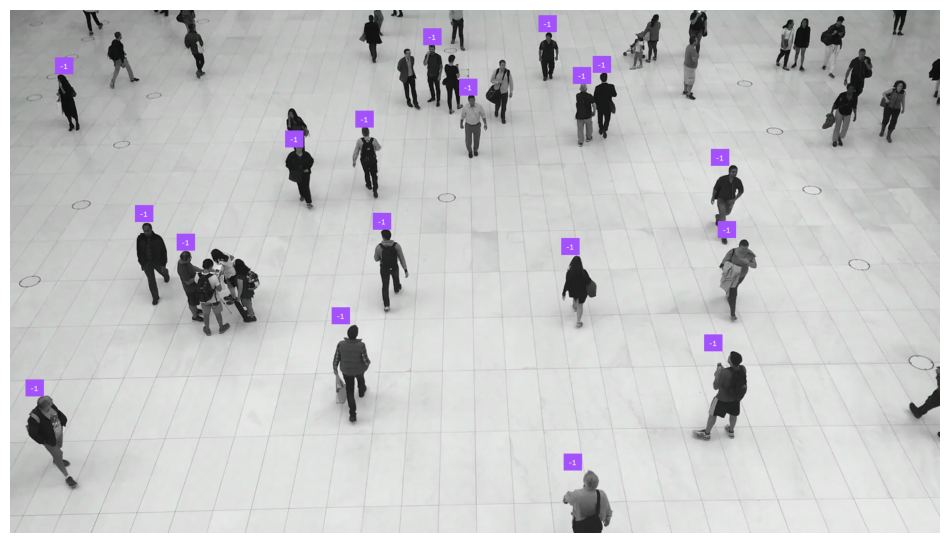

In [17]:
from trackers import ByteTrackTracker

# 加载一个预训练的 yolo11 模型
model = YOLO('yolo11n.pt')

# 根据路径创建一个视频信息对象
video_info = sv.VideoInfo.from_video_path(video_path)

# 创建一个标签标注器，用于为检测结果标注追踪器 ID
label = sv.LabelAnnotator()

# 创建一个 ByteTrack 对象来追踪检测结果
# byte_tracker = sv.ByteTrack(frame_rate = video_info.fps)
# 创建追踪器，参数用法基本一致
byte_tracker = ByteTrackTracker(frame_rate=video_info.fps)

# 从视频路径创建一个帧生成器，用于迭代帧
frame_generator = sv.get_video_frames_generator(video_path)

# 从帧生成器中获取一帧
frame = next(frame_generator)

# 将帧传递给模型以进行推理
result = model(frame)[0]

# 将模型结果转换为 supervision 检测对象
detections = sv.Detections.from_ultralytics(result)

# 使用 byte_tracker 更新检测结果，并添加追踪器 ID
# tracked_detections = byte_tracker.update_with_detections(detections)
# 注意：方法名是 update()，不是 update_with_detections()
tracked_detections = byte_tracker.update(detections)

# 为标签标注器创建带有追踪器 ID 的标签
labels = [ f"{tracker_id}" for tracker_id in tracked_detections.tracker_id ]

# 将标签标注器应用到帧上
annotated_frame = label.annotate(
    scene = frame.copy(),
    detections = tracked_detections,
    labels = labels
)

# 显示帧
sv.plot_image(annotated_frame)

In [20]:
from tqdm import tqdm
from trackers import ByteTrackTracker

# 加载一个预训练的 yolo11 模型
model = YOLO('yolo11n.pt')

# 根据视频路径创建一个视频信息对象
video_info = sv.VideoInfo.from_video_path(video_path)

# 创建一个标签标注器，用于为检测结果标注追踪器 ID
label = sv.LabelAnnotator()

# 创建一个 ByteTracker 对象来追踪检测结果
byte_tracker = ByteTrackTracker(frame_rate=video_info.fps)

# 从视频路径创建一个帧生成器，用于迭代帧
frame_generator = sv.get_video_frames_generator(video_path)

# 创建一个视频接收器上下文管理器，用于保存视频结果
with sv.VideoSink(
    target_path = "./output/trackObjects_result.mp4",
    video_info = video_info
) as sink:
    # 迭代 frame_generator 生成的帧
    for frame in tqdm(frame_generator, total = video_info.total_frames):
        # 将帧传递给模型以运行推理
        result = model(frame)[0]

        # 将模型结果转换为 supervision 检测对象
        detections = sv.Detections.from_ultralytics(result)

        # 使用 byte_tracker 更新检测结果，并添加追踪器 ID
        tracked_detections = byte_tracker.update(detections)

        # 为标签标注器创建带有追踪器 ID 的标签
        labels = [
            f"{tracker_id}" for tracker_id in tracked_detections.tracker_id
        ]

        # 将标签标注器应用到帧上
        annotated_frame = label.annotate(
            scene = frame.copy(),
            detections = tracked_detections,
            labels = labels
        )

        # 将标注过的帧保存到传输视频中
        sink.write_frame(frame = annotated_frame)

  0%|                                                                                                                                                                     | 0/341 [00:00<?, ?it/s]


0: 384x640 18 persons, 34.4ms
Speed: 1.0ms preprocess, 34.4ms inference, 0.6ms postprocess per image at shape (1, 3, 384, 640)


  0%|▍                                                                                                                                                            | 1/341 [00:00<00:34,  9.78it/s]


0: 384x640 19 persons, 37.1ms
Speed: 0.9ms preprocess, 37.1ms inference, 0.7ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 21 persons, 37.1ms
Speed: 1.8ms preprocess, 37.1ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)


  1%|█▍                                                                                                                                                           | 3/341 [00:00<00:21, 15.41it/s]


0: 384x640 21 persons, 38.7ms
Speed: 1.6ms preprocess, 38.7ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 20 persons, 39.6ms
Speed: 1.4ms preprocess, 39.6ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)


... (229 outputs left out)


0: 384x640 17 persons, 32.1ms
Speed: 0.8ms preprocess, 32.1ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 17 persons, 31.7ms
Speed: 1.1ms preprocess, 31.7ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 19 persons, 34.0ms
Speed: 0.8ms preprocess, 34.0ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌| 340/341 [00:15<00:00, 22.80it/s]


0: 384x640 17 persons, 31.0ms
Speed: 0.8ms preprocess, 31.0ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 341/341 [00:16<00:00, 21.28it/s]
